In [ ]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

In [55]:
# Pruebas Oscar

NUM_NODES_INIC = 6     # Número inicial de nodos, m en el paper
NUM_MAX_NODOS = 10
digrafo = nx.DiGraph()

A = 0.5

# Crear un grafo con m nodos, todos ellos empiezan activos
digrafo.add_nodes_from([(i, {'estado': True}) for i in range(NUM_NODES_INIC)])

# En esta lista guardamos los nodos con estado activo
lista_nodos_activos = []
for idx_nodo in range(len(list(digrafo.nodes))):
    if digrafo.nodes[idx_nodo]['estado'] == True:
        lista_nodos_activos.append(idx_nodo)

# Debemos empezar con un grafo completely connected, así que elijo la opción más sencilla
# de conectarlos "en línea":   1 --> 2-->3-->4 etc

for i in range(NUM_NODES_INIC):
    for j in range(NUM_NODES_INIC):
        if i != j:
            digrafo.add_edge(i, j)


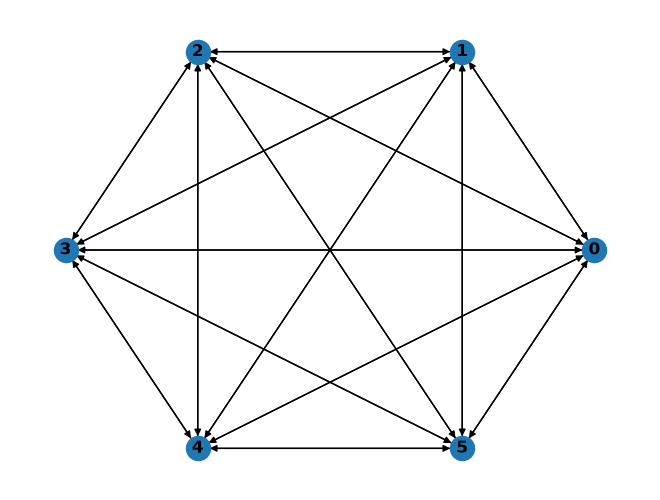

In [56]:
nx.draw(digrafo, with_labels=True, font_weight='bold', pos=nx.circular_layout(digrafo))
plt.show()

In [57]:
#Aquí empiezo las dinámicas (Apartado 3)
for idx_iter in range(NUM_NODES_INIC, NUM_MAX_NODOS):
    # Primero añado un nodo
    digrafo.add_node(idx_iter, estado=True)

    # Segundo, conecto m outgoing links al nodo que acabo de añadir
    nodo_i_llega_a = np.random.choice(lista_nodos_activos, size = NUM_NODES_INIC, replace = False)

    for idx_nodo_a_conectar, nodo_a_conectar in enumerate(nodo_i_llega_a):
        digrafo.add_edge(idx_iter, nodo_a_conectar)
    
    lista_nodos_activos.append(idx_iter)

    desactivado_alguno = False

    while not desactivado_alguno:
        nodo_propongo_desactivar = np.random.choice(lista_nodos_activos)

        # Calcular constante de normalización
        suma = 0
        for elem in lista_nodos_activos:
            suma += 1/(A + len(list(digrafo.neighbors(elem))))
        norm = 1/suma



        prob_desact = (norm)/(A + len(list(digrafo.neighbors(elem))))
        if np.random.uniform() <= prob_desact:
            lista_nodos_activos.remove(nodo_propongo_desactivar)
            desactivado_alguno = True


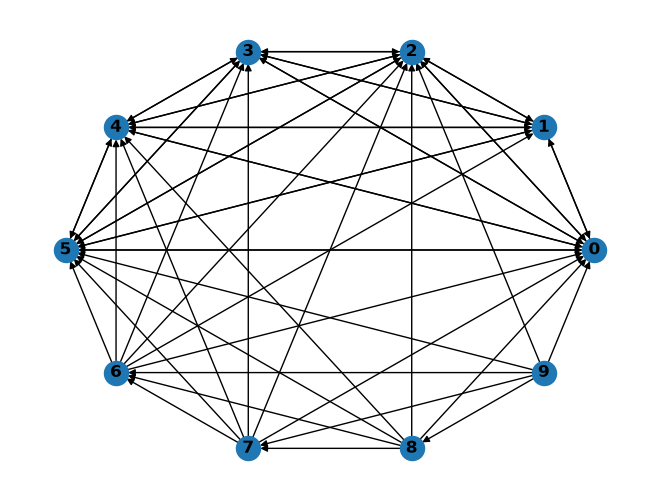

[0, 2, 6, 7, 8, 9]


In [58]:
nx.draw(digrafo, with_labels=True, font_weight='bold', pos=nx.circular_layout(digrafo))
plt.show()
print(lista_nodos_activos)